#ДЗ.9 Markov Chain Monte-Carlo
Реализовать модель из задач 1-3 в pymc.
Получить отклик детектора (распределение полного числа фотоэлектронов) для источника с энергией 1 МэВ в центре детектора. Сравнить с распределением, полученным в задаче 4.
Добавить поглощение с параметрами, аналогичными задаче 6 (опционально).

In [3]:
import numpy as np
import pymc as pm
import matplotlib.pyplot as plt

# Параметры детектора и источника
R = 2.0
N = 40
r = 0.1
a = 0.5

Y = 10000
E = 1.0

# Вероятность попадания фотона на фотокатод
p = N * r**2 / (4 * R**2)

with pm.Model() as model:
    # Число фотонов, попавших на фотокатоды
    n = pm.Binomial("n", n=int(Y * E), p=p)

    # Полное число фотоэлектронов
    Q = pm.Poisson("Q", mu=a * n)


# Сэмплируем модель
with model:
    trace = pm.sample(
        1000,
        tune=1000,
        chains=2,
        cores=1,
        random_seed=42,
        progressbar=False
    )

# Получаем массив значений Q
Q_pymc = trace.posterior["Q"].values.flatten()

print("Среднее число фотоэлектронов:", np.mean(Q_pymc))
print("Стандартное отклонение:", np.std(Q_pymc))


Sequential sampling (2 chains in 1 job)
CompoundStep
>Metropolis: [n]
>Metropolis: [Q]
Sampling 2 chains for 1_000 tune and 1_000 draw iterations (2_000 + 2_000 draws total) took 1 seconds.
We recommend running at least 4 chains for robust computation of convergence diagnostics


Среднее число фотоэлектронов: 126.1535
Стандартное отклонение: 14.268845004063925


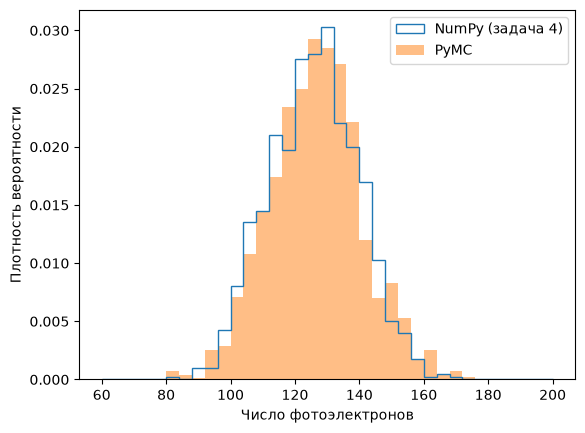

Среднее NumPy: 125.226
Среднее PyMC: 126.1535


In [4]:
# Моделирование из дз.4
n_numpy = np.random.binomial(int(Y * E), p, size=1000)
Q_numpy = np.random.poisson(a * n_numpy)

# Строим два распределения
bins = np.arange(60, 201, 4)

plt.hist(Q_numpy, bins=bins, density=True,histtype="step", label="NumPy (задача 4)")
plt.hist(Q_pymc, bins=bins, density=True,alpha=0.5, label="PyMC")

plt.xlabel("Число фотоэлектронов")
plt.ylabel("Плотность вероятности")
plt.legend()
plt.show()

print("Среднее NumPy:", np.mean(Q_numpy))
print("Среднее PyMC:", np.mean(Q_pymc))


Видно, что распределения, полученные с помощью PyMC и NumPy, хорошо совпадают -> моделирование в PyMC воспроизводит результаты модели детектора (как в дз 1-3)

In [ ]:
# Добавляем поглощение
L = 8.0 #(как в ДЗ.6)
p_abs = p * np.exp(-R / L)

with pm.Model() as model_abs:
    n_abs = pm.Binomial("n", n=int(Y * E), p=p_abs)
    Q_abs = pm.Poisson("Q", mu=a * n_abs)

with model_abs:
    trace_abs = pm.sample(1000, tune=1000, chains=2,
                          cores=1, random_seed=42,
                          progressbar=False)

Q_abs = trace_abs.posterior["Q"].values.flatten()

print("Среднее с поглощением:", np.mean(Q_abs))


Sequential sampling (2 chains in 1 job)
CompoundStep
>Metropolis: [n]
>Metropolis: [Q]
Sampling 2 chains for 1_000 tune and 1_000 draw iterations (2_000 + 2_000 draws total) took 2 seconds.
We recommend running at least 4 chains for robust computation of convergence diagnostics
The effective sample size per chain is smaller than 100 for some parameters.  A higher number is needed for reliable rhat and ess computation. See https://arxiv.org/abs/1903.08008 for details


Среднее с поглощением: 97.281


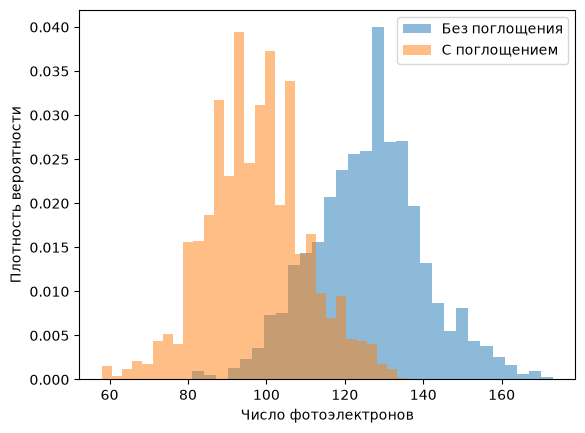

In [ ]:

plt.hist(Q_pymc, bins=30, density=True, alpha=0.5,label="Без поглощения")

plt.hist(Q_abs, bins=30, density=True, alpha=0.5,label="С поглощением")

plt.xlabel("Число фотоэлектронов")
plt.ylabel("Плотность вероятности")
plt.legend()
plt.show()


 Среднее число фотоэлектронов уменьшилось до 97.28, что близко к теоретическому значению 
125 e^{-2/8}= 97.35. Таким образом, поглощение уменьшает собранный заряд детектора примерно на 22%